### Setup, Random Seed (770) & Label Definitions


In [1]:
import hashlib
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import TensorDataset
from IPython.display import display

SEED = 770
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ACCEPTABLE = 0
DEFECTIVE = 1
LABEL_MAP = {"ok_front": ACCEPTABLE, "def_front": DEFECTIVE}
CLASS_NAMES = {ACCEPTABLE: "acceptable", DEFECTIVE: "defective"}

DATA_DIR = Path(os.environ.get("CASTING_DATA_DIR", "casting_512x512"))


def find_class_dir(base_dir: Path, name: str) -> Path:
    matches = sorted(
        p for p in base_dir.rglob(name)
        if p.is_dir() and "casting_data" not in {part.lower() for part in p.parts}
    )
    if not matches:
        raise FileNotFoundError(f"Missing '{name}' under '{base_dir.name}'.")
    return matches[0]


ok_dir = find_class_dir(DATA_DIR, "ok_front")
def_dir = find_class_dir(DATA_DIR, "def_front")
print(f"Labels: defective = {DEFECTIVE}, acceptable = {ACCEPTABLE} | Random seed = {SEED}")


Labels: defective = 1, acceptable = 0 | Random seed = 770


### Data Audit: Dimensions, Class Counts & Exclusions


In [2]:
records, unreadable = [], []

for folder_name, folder_path in [("ok_front", ok_dir), ("def_front", def_dir)]:
    label = LABEL_MAP[folder_name]
    for p in sorted(folder_path.iterdir()):
        if not p.is_file():
            continue
        rel_path = f"{folder_name}/{p.name}"
        try:
            with Image.open(p) as im:
                im.load()
                dims = f"{im.size[0]} x {im.size[1]}"
                arr = np.asarray(im)
                pix_hash = hashlib.sha256(arr.tobytes() + str(arr.shape).encode()).hexdigest()
            records.append(
                {
                    "label": label,
                    "class": CLASS_NAMES[label],
                    "filename": p.name,
                    "rel_path": rel_path,
                    "path": p,
                    "dimensions": dims,
                    "pixel_sha256": pix_hash,
                }
            )
        except Exception as exc:
            unreadable.append(f"{rel_path} ({type(exc).__name__})")

raw_df = pd.DataFrame(records).sort_values(["label", "filename"]).reset_index(drop=True)

kept_idx, same_label_dups, conflicting_dups = [], [], []
for _, grp in raw_df.groupby("pixel_sha256", sort=False):
    grp_sorted = grp.sort_values(["label", "filename"])
    if grp_sorted["label"].nunique() > 1:
        conflicting_dups.extend(grp_sorted["rel_path"].tolist())
    else:
        kept_idx.append(grp_sorted.index[0])
        same_label_dups.extend(grp_sorted["rel_path"].iloc[1:].tolist())

cleaned_df = raw_df.loc[kept_idx].sort_values(["label", "filename"]).reset_index(drop=True)

audit_df = pd.DataFrame(
    [
        {
            "Class": f"{CLASS_NAMES[lbl]} ({lbl})",
            "Count": int((cleaned_df["label"] == lbl).sum()),
            "Dimensions": ", ".join(sorted(cleaned_df.loc[cleaned_df["label"] == lbl, "dimensions"].unique())),
        }
        for lbl in [ACCEPTABLE, DEFECTIVE]
    ]
    + [
        {
            "Class": "Total",
            "Count": len(cleaned_df),
            "Dimensions": ", ".join(sorted(cleaned_df["dimensions"].unique())),
        }
    ]
)
display(audit_df)

total_excluded = len(unreadable) + len(same_label_dups) + len(conflicting_dups)
print(
    f"Exclusions -> unreadable: {len(unreadable)}, same-label duplicates: {len(same_label_dups)}, "
    f"conflicting-label duplicates: {len(conflicting_dups)}, total excluded: {total_excluded}."
)
if unreadable:
    print("Unreadable:", unreadable)
if same_label_dups:
    print("Excluded same-label duplicates:", same_label_dups)
if conflicting_dups:
    print("Set-aside conflicting-label duplicates:", conflicting_dups)


,Class,Count,Dimensions
0,acceptable (0),519,512 x 512
1,defective (1),781,512 x 512
2,Total,1300,512 x 512


Exclusions -> unreadable: 0, same-label duplicates: 0, conflicting-label duplicates: 0, total excluded: 0.


### Labeled Grid of 8 Sample Images


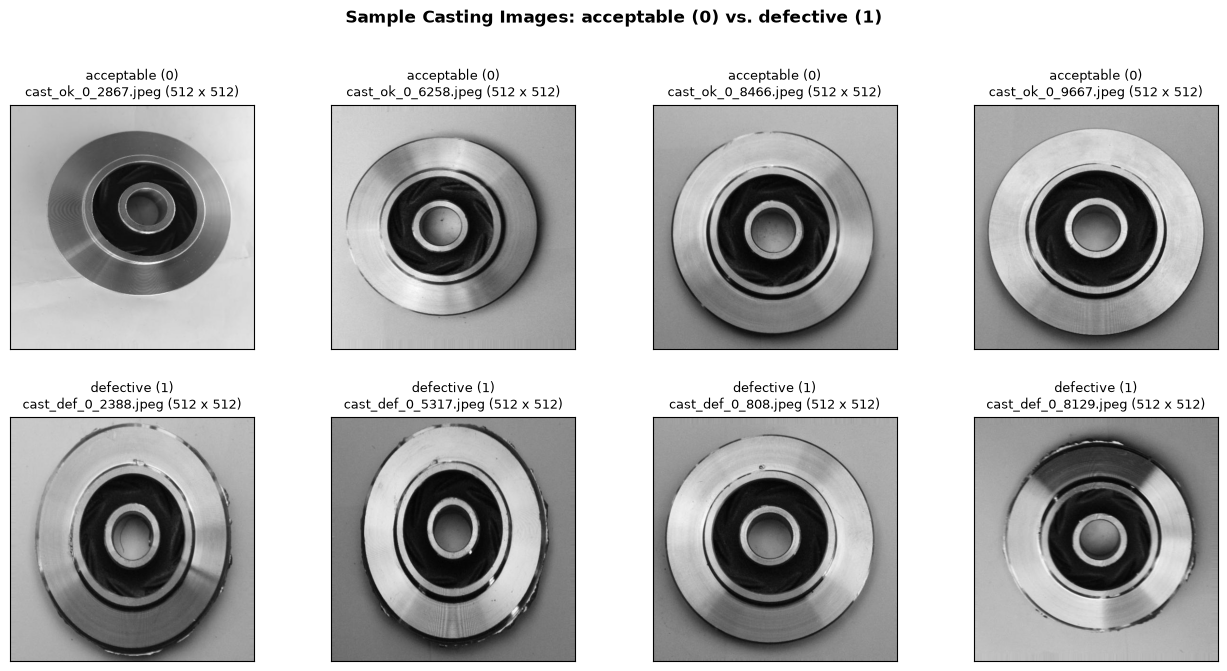

In [3]:
rng = np.random.default_rng(SEED)
sample_rows = []
for lbl in [ACCEPTABLE, DEFECTIVE]:
    idx = sorted(rng.choice(cleaned_df[cleaned_df["label"] == lbl].index.to_numpy(), size=4, replace=False))
    sample_rows.extend(cleaned_df.loc[i] for i in idx)

fig, axes = plt.subplots(2, 4, figsize=(13, 6.8))
for ax, row in zip(axes.flat, sample_rows):
    with Image.open(row["path"]) as im:
        ax.imshow(im)
    ax.set_title(f"{row['class']} ({row['label']})\n{row['filename']} ({row['dimensions']})", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Sample Casting Images: acceptable (0) vs. defective (1)", fontsize=12, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.subplots_adjust(hspace=0.28)
plt.show()


### Stratified Train / Validation / Test Split (70% / 15% / 15%, Seed 770)


In [4]:
train_df, temp_df = train_test_split(
    cleaned_df, test_size=0.30, stratify=cleaned_df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)
train_df, val_df, test_df = (
    train_df.reset_index(drop=True),
    val_df.reset_index(drop=True),
    test_df.reset_index(drop=True),
)

splits = [("Train", train_df), ("Validation", val_df), ("Test", test_df)]
split_table = pd.DataFrame(
    [
        {
            "Split": name,
            "Total": len(df_s),
            "Share": f"{100.0 * len(df_s) / len(cleaned_df):.1f}%",
            "acceptable (0)": int((df_s["label"] == ACCEPTABLE).sum()),
            "defective (1)": int((df_s["label"] == DEFECTIVE).sum()),
        }
        for name, df_s in splits
    ]
)
display(split_table)

for name, df_s in splits:
    files = sorted(df_s["rel_path"].tolist())
    print(f"\n{name.upper()} ({len(files)} images):")
    for i in range(0, len(files), 5):
        print("  " + "  ".join(f"{f:<30}" for f in files[i : i + 5]).rstrip())


,Split,Total,Share,acceptable (0),defective (1)
0,Train,910,70.0%,363,547
1,Validation,195,15.0%,78,117
2,Test,195,15.0%,78,117



TRAIN (910 images):
  def_front/cast_def_0_0.jpeg     def_front/cast_def_0_1015.jpeg  def_front/cast_def_0_102.jpeg   def_front/cast_def_0_1053.jpeg  def_front/cast_def_0_1055.jpeg
  def_front/cast_def_0_1087.jpeg  def_front/cast_def_0_1091.jpeg  def_front/cast_def_0_1112.jpeg  def_front/cast_def_0_1115.jpeg  def_front/cast_def_0_1123.jpeg
  def_front/cast_def_0_1137.jpeg  def_front/cast_def_0_1139.jpeg  def_front/cast_def_0_1145.jpeg  def_front/cast_def_0_1147.jpeg  def_front/cast_def_0_1155.jpeg
  def_front/cast_def_0_1157.jpeg  def_front/cast_def_0_1187.jpeg  def_front/cast_def_0_1188.jpeg  def_front/cast_def_0_1225.jpeg  def_front/cast_def_0_1226.jpeg
  def_front/cast_def_0_1257.jpeg  def_front/cast_def_0_1261.jpeg  def_front/cast_def_0_127.jpeg   def_front/cast_def_0_1283.jpeg  def_front/cast_def_0_1286.jpeg
  def_front/cast_def_0_1359.jpeg  def_front/cast_def_0_1381.jpeg  def_front/cast_def_0_1411.jpeg  def_front/cast_def_0_1427.jpeg  def_front/cast_def_0_1432.jpeg
  def_front/c

### Grayscale 64 x 64 Preprocessing Scaled to [0, 1]


In [5]:
IMG_SIZE = (64, 64)


def preprocess_image(path: Path) -> np.ndarray:
    with Image.open(path) as im:
        gray = im.convert("L").resize(IMG_SIZE, Image.Resampling.BILINEAR)
        return np.asarray(gray, dtype=np.float32) / 255.0


def build_arrays(df_s: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    X = np.stack([preprocess_image(p) for p in df_s["path"]], axis=0)
    y = df_s["label"].to_numpy(dtype=np.int64, copy=True)
    return X, y


X_train, y_train = build_arrays(train_df)
X_val, y_val = build_arrays(val_df)
X_test, y_test = build_arrays(test_df)

X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

train_dataset = TensorDataset(torch.from_numpy(X_train).unsqueeze(1), torch.from_numpy(y_train))
val_dataset = TensorDataset(torch.from_numpy(X_val).unsqueeze(1), torch.from_numpy(y_val))
test_dataset = TensorDataset(torch.from_numpy(X_test).unsqueeze(1), torch.from_numpy(y_test))

prep_table = pd.DataFrame(
    [
        {
            "Split": name,
            "Image": str(X.shape),
            "Flat": str(X_flat.shape),
            "Tensor": str(tuple(ds.tensors[0].shape)),
            "Dtype": str(X.dtype),
            "Min": f"{X.min():.4f}",
            "Max": f"{X.max():.4f}",
        }
        for name, X, X_flat, ds in [
            ("Train", X_train, X_train_flat, train_dataset),
            ("Validation", X_val, X_val_flat, val_dataset),
            ("Test", X_test, X_test_flat, test_dataset),
        ]
    ]
)
display(prep_table)


,Split,Image,Flat,Tensor,Dtype,Min,Max
0,Train,"(910, 64, 64)","(910, 4096)","(910, 1, 64, 64)",float32,0.0235,1.0000
1,Validation,"(195, 64, 64)","(195, 4096)","(195, 1, 64, 64)",float32,0.0235,1.0000
2,Test,"(195, 64, 64)","(195, 4096)","(195, 1, 64, 64)",float32,0.0275,1.0000


### Setup and helpers

In [6]:
import platform, sys, time, copy, warnings
import sklearn
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | torch {torch.__version__} | device {DEVICE} | seed {SEED}")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def defect_metrics(y_true, y_pred):
    return {
        "Precision": precision_score(y_true, y_pred, pos_label=DEFECTIVE, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=DEFECTIVE, zero_division=0),
        "F1": f1_score(y_true, y_pred, pos_label=DEFECTIVE, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_pred),
    }

THRESHOLD = 0.5  # fixed decision rule: P(defective) >= 0.5 -> defective

Python 3.14.6 | numpy 2.4.6 | pandas 3.0.3 | scikit-learn 1.9.0 | torch 2.15.0+cpu | device cpu | seed 770


### Baseline (logistic regression)

In [7]:
set_seed()
log_reg = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=SEED)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    t0 = time.perf_counter()
    log_reg.fit(X_train_flat, y_train)
    lr_train_time = time.perf_counter() - t0

conv = [str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)]
print("Settings:", log_reg.get_params())
print(f"Iterations: {int(log_reg.n_iter_[0])}/{log_reg.max_iter} | time {lr_train_time:.2f}s")
print("Convergence issue:", conv[0].splitlines()[0] if conv else "none")

lr_val_pred = (log_reg.predict_proba(X_val_flat)[:, 1] >= THRESHOLD).astype(int)
lr_val_metrics = defect_metrics(y_val, lr_val_pred)
print({k: round(v, 4) for k, v in lr_val_metrics.items()})

Settings: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 770, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Iterations: 498/1000 | time 2.22s
Convergence issue: none
{'Precision': 0.8684, 'Recall': 0.8462, 'F1': 0.8571, 'Accuracy': 0.8308}


### Baseline settings and convergence
Logistic regression (`C=1.0`, L2 penalty, `lbfgs`, `max_iter=1000`, `random_state=770`) on the 4,096 flattened pixels scaled to [0, 1]. It converged in 498 of 1,000 iterations with no convergence warning, in 2.22 s.

### CNN design choices
- **Architecture:** three blocks of Conv2d (3x3) + ReLU + MaxPool (16, 32, 64 filters), then Flatten, a 128-unit linear layer with ReLU, dropout, and a 1-logit output.Small enough to train on a CPU, enough depth to pick up local textures and cracks.
- **Loss:** BCEWithLogitsLoss, since this is binary classification with one logit.
- **Optimizer:** Adam, learning rate 1e-3, a reliable default that needs little tuning.
- **Batch size:** 32, light on memory and gives many updates per epoch on 910 images.
- **Training duration:** 15 epochs; the checkpoint with the lowest validation loss is kept.

### Compare a baseline and a CNN

In [8]:
class SmallCNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64))   # 64 -> 32 -> 16 -> 8
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, 1)
        )
    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)

BATCH_SIZE, EPOCHS, LR = 32, 15, 1e-3

@torch.no_grad()
def predict_probs(model, dataset):
    model.eval()
    loader = DataLoader(dataset, batch_size=128, shuffle=False)
    return torch.cat([torch.sigmoid(model(xb.to(DEVICE))).cpu() for xb, _ in loader]).numpy()

def train_cnn(dropout, lr=LR, epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED):
    set_seed(seed)
    model = SmallCNN(dropout=dropout).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=g)
    val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

    hist = {"train_loss": [], "val_loss": []}
    best_val, best_state, best_epoch = float("inf"), None, 0
    t0 = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train(); tot, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.float().to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            tot += loss.item() * len(xb); n += len(xb)
        model.eval(); vt, vn = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                vt += loss_fn(model(xb.to(DEVICE)), yb.float().to(DEVICE)).item() * len(xb); vn += len(xb)
        hist["train_loss"].append(tot / n); hist["val_loss"].append(vt / vn)
        if hist["val_loss"][-1] < best_val:
            best_val, best_epoch = hist["val_loss"][-1], epoch
            best_state = copy.deepcopy(model.state_dict())
    elapsed = time.perf_counter() - t0
    model.load_state_dict(best_state)
    return model, hist, best_epoch, elapsed

cnn_a, hist_a, best_ep_a, time_a = train_cnn(dropout=0.0)
val_metrics_a = defect_metrics(y_val, (predict_probs(cnn_a, val_dataset) >= THRESHOLD).astype(int))
print(f"CNN-A (dropout 0.0): best epoch {best_ep_a}, time {time_a:.1f}s")
print({k: round(v, 4) for k, v in val_metrics_a.items()})

CNN-A (dropout 0.0): best epoch 15, time 37.0s
{'Precision': 0.9159, 'Recall': 0.8376, 'F1': 0.875, 'Accuracy': 0.8564}


In [9]:
print("Train loss, last epoch:     ", round(hist_a["train_loss"][-1], 4))
print("Validation loss, last epoch:", round(hist_a["val_loss"][-1], 4))
print("Best validation loss:       ", round(min(hist_a["val_loss"]), 4))

Train loss, last epoch:      0.2284
Validation loss, last epoch: 0.3349
Best validation loss:        0.3349


**Expectation for the controlled experiment (dropout 0.0 vs 0.5):** CNN-A reached a training loss of 0.2284 against a validation loss of 0.3349, so there is a moderate gap, but validation loss was still at its lowest value at epoch 15, so the model has not yet overfit within the 15-epoch budget. We therefore expect dropout 0.5 to make little difference to validation F1 (CNN-A: 0.875). It may reduce the train/validation gap slightly by raising the training loss, and because dropout slows learning, validation loss and recall may be equal or slightly worse at epoch 15. We will treat an F1 difference of only a few images’ worth on the 195-image validation set as within noise rather than a real effect.

### controlled experiment (CNN-B, dropout 0.5) and loss curves

CNN-B (dropout 0.5): best epoch 15, time 35.7s
{'Precision': 0.808, 'Recall': 0.8632, 'F1': 0.8347, 'Accuracy': 0.7949}


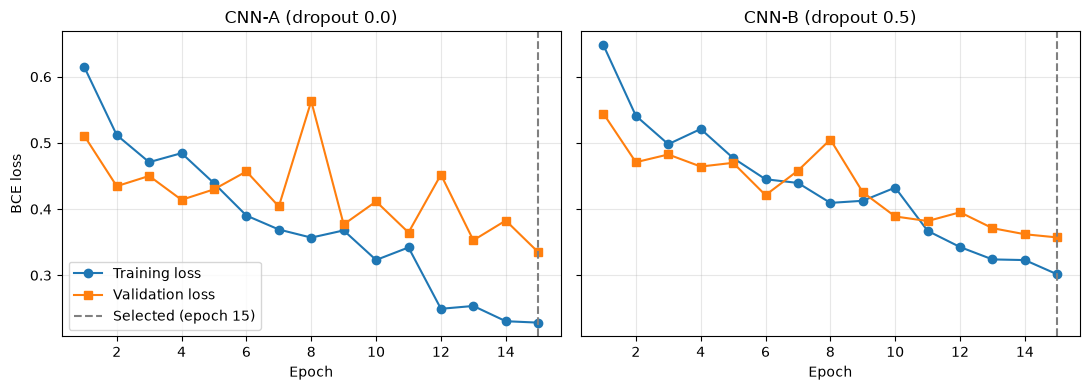

In [10]:
cnn_b, hist_b, best_ep_b, time_b = train_cnn(dropout=0.5)
val_metrics_b = defect_metrics(y_val, (predict_probs(cnn_b, val_dataset) >= THRESHOLD).astype(int))
print(f"CNN-B (dropout 0.5): best epoch {best_ep_b}, time {time_b:.1f}s")
print({k: round(v, 4) for k, v in val_metrics_b.items()})

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, h, ep, title in [(axes[0], hist_a, best_ep_a, "CNN-A (dropout 0.0)"),
                         (axes[1], hist_b, best_ep_b, "CNN-B (dropout 0.5)")]:
    xs = range(1, EPOCHS + 1)
    ax.plot(xs, h["train_loss"], marker="o", label="Training loss")
    ax.plot(xs, h["val_loss"], marker="s", label="Validation loss")
    ax.axvline(ep, color="gray", linestyle="--", label=f"Selected (epoch {ep})")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
axes[0].set_ylabel("BCE loss"); axes[0].legend()
plt.tight_layout(); plt.show()

In [11]:
for name, h in [("CNN-A (dropout 0.0)", hist_a), ("CNN-B (dropout 0.5)", hist_b)]:
    tr, va = h["train_loss"][-1], h["val_loss"][-1]
    print(f"{name}: train loss {tr:.4f} | val loss {va:.4f} | gap {va - tr:.4f}")

CNN-A (dropout 0.0): train loss 0.2284 | val loss 0.3349 | gap 0.1065
CNN-B (dropout 0.5): train loss 0.3013 | val loss 0.3572 | gap 0.0558


### Interpretation of the Controlled Experiment (dropout 0.0 vs 0.5)

Only dropout changed (CNN-A: 0.0, CNN-B: 0.5); the split, preprocessing, architecture, optimizer, learning rate, batch size, epochs and seed were identical.

| Model | Precision | Recall | F1 | Accuracy |
|---|---|---|---|---|
| CNN-A (dropout 0.0) | 0.9159 | 0.8376 | 0.8750 | 0.8564 |
| CNN-B (dropout 0.5) | 0.8080 | 0.8632 | 0.8347 | 0.7949 |

**Expectation vs. result:** The result partly matched our expectation: as we predicted, dropout raised the training loss, narrowed the train/validation gap and left validation loss slightly worse. However, validation F1 fell from 0.875 to 0.835 (about 12 more misclassified images out of 195), which is larger than the “little difference” we predicted, and recall rose (0.838 to 0.863) rather than staying equal or dropping.

**Observations:** Dropout made training smoother and narrowed the gap between training and validation loss, but validation F1 fell from 0.875 to 0.835. CNN-B had slightly higher recall (fewer missed defects) but much lower precision (more good parts rejected).

**Caveat:** This is one seed, one split and a 195-image validation set, so it shows that dropout 0.5 scored lower here at 15 epochs.CNN-B's loss was still falling at epoch 15, so it may simply need more training.